# Lab 11.2: Six Maps, One Image

Chapter 11, Where the Network Looks. A small convolutional network is trained on synthetic, chest-radiograph-like images in which positives carry a faint opacity. You compute six kinds of attribution map, check the completeness of Integrated Gradients, and measure how much of each map lands on the true finding. **These are not medical images and the network is not a medical model.** Run the cells in order; nothing needs editing.

## Part A. Data and model

The images are 32 by 32 pixels. Here the corner token is independent of the label (half of all images carry it), so a sound model has no reason to use it.

In [1]:
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from sklearn.metrics import roc_auc_score
torch.set_num_threads(4)
print("numpy", np.__version__, "| torch", torch.__version__)

S = 32
yy, xx = np.mgrid[0:S, 0:S]
BODY = ((xx - 15.5) / 14.5) ** 2 + ((yy - 18) / 15) ** 2 < 1
LUNGS = (((xx - 9.5) / 4.8) ** 2 + ((yy - 17) / 9) ** 2 < 1) | (((xx - 21.5) / 4.8) ** 2 + ((yy - 17) / 9) ** 2 < 1)
MARK = np.zeros((S, S), bool); MARK[2:7, 2:4] = True; MARK[5:7, 2:6] = True   # the L-shaped token


def make_images(n, p_pos, p_mark_pos, p_mark_neg, rng, amp=0.22):
    """Synthetic radiograph-like images. Returns images, labels, token flags, opacity masks.
    p_mark_pos / p_mark_neg: chance that a positive / negative image carries the token."""
    X = np.zeros((n, S, S), np.float32); y = (rng.random(n) < p_pos).astype(np.float32)
    m = np.where(y == 1, rng.random(n) < p_mark_pos, rng.random(n) < p_mark_neg)
    les = np.zeros((n, S, S), bool)
    lung_pix = np.argwhere(LUNGS & (yy > 11) & (yy < 24))
    for i in range(n):
        img = np.where(BODY, 0.62, 0.05) - np.where(LUNGS, 0.36, 0.0)
        img = img + gaussian_filter(rng.normal(0, 0.18, (S, S)), 3) + 0.05 * (rng.random() - 0.5)
        if y[i] == 1:
            cy, cx = lung_pix[rng.integers(len(lung_pix))]
            blob = np.exp(-((yy - cy) ** 2 + (xx - cx) ** 2) / (2 * 2.2 ** 2))
            img = img + amp * blob * LUNGS
            les[i] = blob > 0.3
        if m[i]:
            img = np.where(MARK, 0.95, img)
        X[i] = np.clip(img + rng.normal(0, 0.04, (S, S)), 0, 1)
    return X, y, m, les


class Net(nn.Module):
    def __init__(s):
        super().__init__()
        s.c1 = nn.Conv2d(1, 8, 3, padding=1); s.c2 = nn.Conv2d(8, 16, 3, padding=1)
        s.c3 = nn.Conv2d(16, 16, 3, padding=1); s.fc = nn.Linear(16, 1)
    def features(s, x):
        x = F.max_pool2d(F.relu(s.c1(x)), 2); x = F.max_pool2d(F.relu(s.c2(x)), 2)
        return F.relu(s.c3(x))
    def forward(s, x):
        return s.fc(s.features(x).mean((2, 3))).squeeze(-1)      # a logit


def train(X, y, seed=0, epochs=25):
    torch.manual_seed(seed); net = Net(); opt = torch.optim.Adam(net.parameters(), 3e-3)
    Xt, yt = torch.tensor(X[:, None]), torch.tensor(y); g = torch.Generator().manual_seed(seed)
    for _ in range(epochs):
        for idx in torch.randperm(len(X), generator=g).split(64):
            opt.zero_grad(); F.binary_cross_entropy_with_logits(net(Xt[idx]), yt[idx]).backward(); opt.step()
    return net.eval()


def predict(net, X):
    with torch.no_grad():
        return torch.sigmoid(net(torch.tensor(X[:, None]))).numpy()


def logit(net, x):
    with torch.no_grad():
        return net(torch.tensor(np.asarray(x, np.float32)[None, None])).item()


numpy 2.2.6 | torch 2.6.0


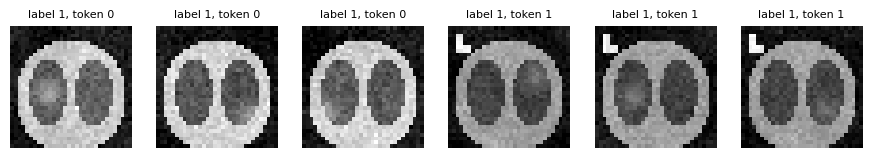

In [2]:
rng = np.random.default_rng(1)
_ = make_images(3000, 0.5, 0.9, 0.1, rng)          # drawn only to keep the random stream identical to the book's figures
Xtr, ytr, mtr, _ = make_images(3000, 0.5, 0.5, 0.5, rng)
_ = make_images(1000, 0.5, 0.9, 0.1, rng)
Xte, yte, mte, lte = make_images(1000, 0.5, 0.5, 0.5, rng)
fig, axes = plt.subplots(1, 6, figsize=(11, 2.2))
for ax, i in zip(axes, range(6)):
    ax.imshow(Xte[i], cmap='gray'); ax.set_title(f'label {int(yte[i])}, token {int(mte[i])}', fontsize=8); ax.axis('off')
plt.show()

In [3]:
SEED = 0   # optional edit at the end: try 1 or 2 and rerun everything
net = train(Xtr, ytr, seed=SEED)
print('test AUROC: %.3f' % roc_auc_score(yte, predict(net, Xte)))   # Checkpoint 1

test AUROC: 0.969


## Part B. Six methods on one image

Each function below is written out so that you can read every step. Libraries such as Captum implement the same methods for any PyTorch model.

In [4]:
def _t(x):
    return torch.tensor(np.asarray(x, np.float32)[None, None])

def gradient(net, x):
    xt = _t(x).requires_grad_(True); net(xt).sum().backward(); return xt.grad[0, 0].numpy()

def grad_x_input(net, x):
    return gradient(net, x) * x

def smoothgrad(net, x, sigma=0.15, n=50, seed=0):
    rng = np.random.default_rng(seed)
    return np.mean([gradient(net, x + rng.normal(0, sigma, x.shape).astype(np.float32)) for _ in range(n)], 0)

def integrated_gradients(net, x, base=None, steps=64):
    base = np.zeros_like(x) if base is None else base
    alphas = (np.arange(steps) + 0.5) / steps                          # midpoint rule
    path = np.stack([base + a * (x - base) for a in alphas]).astype(np.float32)
    pt = torch.tensor(path[:, None]).requires_grad_(True); net(pt).sum().backward()
    return (x - base) * pt.grad[:, 0].numpy().mean(0)

def expected_gradients(net, x, refs, n=200, seed=0):
    rng = np.random.default_rng(seed)
    r = refs[rng.integers(len(refs), size=n)]; a = rng.random(n)[:, None, None]
    pt = torch.tensor((r + a * (x - r)).astype(np.float32)[:, None]).requires_grad_(True); net(pt).sum().backward()
    return ((x - r) * pt.grad[:, 0].numpy()).mean(0)

def gradcam(net, x):
    A = net.features(_t(x)); A.retain_grad(); net.fc(A.mean((2, 3))).sum().backward()
    w = A.grad[0].mean((1, 2)); cam = F.relu((w[:, None, None] * A[0]).sum(0))
    return F.interpolate(cam[None, None], size=(S, S), mode="bilinear", align_corners=False)[0, 0].detach().numpy()

def occlusion(net, x, size=4, stride=2):
    fill = x.mean(); base = logit(net, x); heat = np.zeros_like(x); cnt = np.zeros_like(x)
    for r in range(0, S - size + 1, stride):
        for c in range(0, S - size + 1, stride):
            z = x.copy(); z[r:r + size, c:c + size] = fill
            heat[r:r + size, c:c + size] += base - logit(net, z); cnt[r:r + size, c:c + size] += 1
    return heat / np.maximum(cnt, 1)

class GuidedReLU(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x):
        ctx.save_for_backward(x); return x.clamp(min=0)
    @staticmethod
    def backward(ctx, g):
        x, = ctx.saved_tensors; return g * (x > 0) * (g > 0)

def guided_backprop(net, x):
    xt = _t(x).requires_grad_(True); r = GuidedReLU.apply
    h = F.max_pool2d(r(net.c1(xt)), 2); h = F.max_pool2d(r(net.c2(h)), 2); h = r(net.c3(h))
    net.fc(h.mean((2, 3))).sum().backward(); return xt.grad[0, 0].numpy()

def shares(a, lesion):
    """Share of total |attribution| on the token and on the opacity."""
    a = np.abs(a); a = a / (a.sum() + 1e-12); return a[MARK].sum(), a[lesion].sum()

def show(ax, a, title, lesion=None, cmap="magma"):
    ax.imshow(a, cmap=cmap); ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])
    if lesion is not None:
        ax.contour(lesion, levels=[0.5], colors=["cyan"], linewidths=1, linestyles="--")


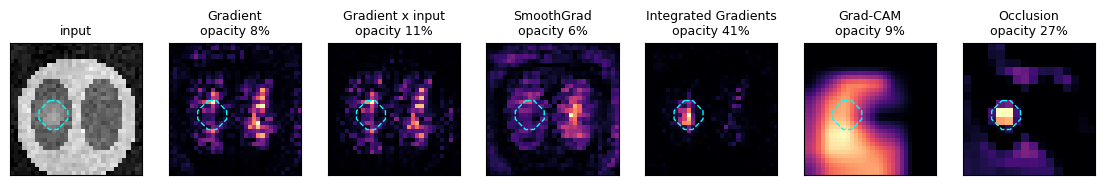

In [5]:
HEALTHY = Xtr[ytr == 0]; MNEG = HEALTHY.mean(0).astype(np.float32)   # average healthy image
pos = np.where((yte == 1) & ~mte)[0]   # positives without the token
i = pos[0]; x = Xte[i]
maps = {'Gradient': gradient(net, x), 'Gradient x input': grad_x_input(net, x), 'SmoothGrad': smoothgrad(net, x),
        'Integrated Gradients': integrated_gradients(net, x, base=MNEG), 'Grad-CAM': gradcam(net, x),
        'Occlusion': np.clip(occlusion(net, x), 0, None)}
fig, axes = plt.subplots(1, 7, figsize=(14, 2.4))
show(axes[0], x, 'input', lte[i], cmap='gray')
for ax, (k, a) in zip(axes[1:], maps.items()):
    t, l = shares(a, lte[i]); show(ax, np.abs(a), f'{k}\nopacity {100*l:.0f}%', lte[i])
plt.show()

## Part C. Completeness of Integrated Gradients

The attributions should add up to the change in the logit between the baseline and the input. Watch the error shrink as the number of steps grows, and compare with gradient times (input minus baseline).

In [6]:
change = logit(net, x) - logit(net, MNEG)
print('logit change from baseline to input: %.3f' % change)
for steps in (2, 4, 8, 16, 32, 64, 128):
    a = integrated_gradients(net, x, base=MNEG, steps=steps)
    print(f'steps {steps:4d}: sum {a.sum():8.3f}   error {abs(a.sum() - change):.4f}')   # Checkpoint 2
print('gradient x (input - baseline) sums to %.3f' % (gradient(net, x) * (x - MNEG)).sum())

logit change from baseline to input: 11.449
steps    2: sum   12.347   error 0.8981
steps    4: sum   10.918   error 0.5307
steps    8: sum   11.680   error 0.2315
steps   16: sum   11.324   error 0.1252
steps   32: sum   11.462   error 0.0129
steps   64: sum   11.456   error 0.0074
steps  128: sum   11.453   error 0.0040
gradient x (input - baseline) sums to 13.082


## Part D. How often does each map land on the opacity?

For 60 positive test images we record two scores per method: the share of total attribution inside the opacity (the opacity covers about 3.6 percent of the image), and whether the hottest pixel falls within two pixels of the opacity.

In [7]:
from scipy.ndimage import binary_dilation
funcs = {'Gradient': lambda x: gradient(net, x), 'Gradient x input': lambda x: grad_x_input(net, x),
         'SmoothGrad': lambda x: smoothgrad(net, x, n=20), 'Integrated Gradients': lambda x: integrated_gradients(net, x, base=MNEG),
         'Grad-CAM': lambda x: gradcam(net, x), 'Occlusion': lambda x: np.clip(occlusion(net, x), 0, None)}
print(f"{'method':22s} {'opacity share':>14s} {'peak on opacity':>16s}")
for k, f in funcs.items():
    sh, hit = [], []
    for j in pos[:60]:
        a = np.abs(f(Xte[j])); sh.append(shares(a, lte[j])[1])
        hit.append(binary_dilation(lte[j], iterations=2)[np.unravel_index(np.argmax(a), a.shape)])
    print(f'{k:22s} {np.mean(sh):14.3f} {np.mean(hit):16.2f}')   # Checkpoint 3

method                  opacity share  peak on opacity
Gradient                        0.105             0.63
Gradient x input                0.152             0.72


SmoothGrad                      0.063             0.22


Integrated Gradients            0.314             0.98
Grad-CAM                        0.070             0.23


Occlusion                       0.146             0.73


## Questions

1. Which method answers the sensitivity question, and which the contribution question? Use Part C in your answer.
2. Grad-CAM localizes poorly here, yet a large chest radiograph benchmark (Saporta et al., 2022) found it the best of seven methods. Give two reasons both can be true.
3. SmoothGrad has the lowest opacity share in Part D. Is SmoothGrad therefore wrong? What does it answer?
4. Write one sentence per method, for a validator, on what its map can and cannot be used for.
5. Optional: set `SEED = 1` in Part A, rerun all cells and compare Checkpoint 3. What does a change in the ranking of methods tell you about benchmark rankings?